---

# Final Pipeline — Logistic Regression

**Penanggung jawab:** Emilio Justin (13524043)  
**Kelompok:** G03 — FiveAgents  
**Varian:** L1, L2, dan Elastic Net

Implementasi berada di `src/experiments/logistic_regression/`.


---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Model Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)

---

# Introduction <a name="1"></a>

---

## Overview

Targetnya adalah pembatalan booking: 0 berarti tidak batal, 1 berarti batal.
Model memakai informasi tamu, lama menginap, waktu pemesanan, channel, harga,
permintaan khusus, dan riwayat booking.

## Aim

Menjalankan tiga konfigurasi final dengan preprocessing yang sama. Perbedaannya
ada pada penalti L1, L2, atau campuran Elastic Net. Model dengan macro F1 validasi
tertinggi digunakan untuk CSV utama LR, CSV setiap regularisasi juga disimpan.

## Metric

Metrik utama adalah *Macro F1* pada validation dengan kedua kelas diberi bobot sama.

$$\mathrm{MacroF1}=\frac{1}{2}\sum_{c\in\{0,1\}}\mathrm{F1}_c$$

Gunakan `labels=[0, 1]`, `average='macro'`, dan `zero_division=0`.

## Dataset

Input berupa `train.csv` dan `test.csv`. Dataset saat finalisasi berisi 27.373
booking berlabel dan 6.844 booking test. `id` dibaca sebagai string dan tidak
menjadi fitur. Target `is_canceled` hanya tersedia pada train.

## Approach

Split kelompok menggunakan seed 42 dan sekitar 20% dari setiap kelas sebagai
validasi. Konfigurasi dan threshold sudah ditetapkan dari pencarian sebelumnya
pada bagian latih. Tiga fold internal diulang untuk memeriksa konfigurasi tersebut,
tanpa pencarian parameter baru. Test dipakai untuk prediksi submission.

---

# Initialization <a name="2"></a>

---

Bagian ini menyiapkan pustaka, lokasi kode, dataset, dan folder output.

## Environment Setup

Gunakan environment proyek. Pada
Kaggle atau Google Colab, tambahkan dataset CSV dan tiga file source `.py` sebagai input notebook.

In [1]:
# Jika diperlukan: %pip install numpy pandas scikit-learn matplotlib threadpoolctl

### Insight

Perhitungan inti model menggunakan NumPy dan modul `math`. Scikit-learn digunakan
untuk preprocessing, metrik, pembagian CV, dan model pembanding. Versi pustaka
dicetak agar lingkungan run dapat dicatat.

## Import Libraries

`SOURCE_DIR` dicari dari repository, direktori kerja, atau input Kaggle. Jika
terdapat lebih dari satu kandidat, isi `SOURCE_DIR` dengan folder yang dipilih.

In [2]:
import os
import random
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Isi kedua path ini hanya jika pencarian otomatis tidak menemukan input yang tepat.
SOURCE_DIR = None
DATA_DIR = None
project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'data/train.csv').is_file()
                     and (p / 'data/test.csv').is_file()), None)

if SOURCE_DIR is None:
    candidates = [Path.cwd()]
    if project_root is not None:
        candidates.insert(0, project_root / 'src/experiments/logistic_regression')
    if Path('/kaggle/input').is_dir():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('experiments.py')]
    candidates = sorted({p.resolve() for p in candidates
                         if all((p / file).is_file() for file in
                                ['experiments.py', 'preprocessing.py', 'logistic_regression.py'])})
    if len(candidates) != 1:
        raise ValueError('Isi SOURCE_DIR dengan folder ketiga file .py.')
    SOURCE_DIR = candidates[0]
SOURCE_DIR = Path(SOURCE_DIR).resolve()
sys.path.insert(0, str(SOURCE_DIR))

from experiments import (
    FINAL_CONFIGS, VARIANT_NAMES, compare_sklearn, cross_validate,
    data_hashes, evaluate_variants, fit_final_models, fit_preprocessor,
    load_model_bundle, make_contract_split, make_submissions, select_variant,
    transform_features,
)
from preprocessing import FEATURE_CONFIG

print('Modul Logistic Regression berhasil dimuat.')
print('Versi:', {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'matplotlib']})


Modul Logistic Regression berhasil dimuat.
Versi: {'numpy': '2.5.4', 'pandas': '3.1.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}


## Settings

In [3]:
if DATA_DIR is None:
    if project_root is not None:
        DATA_DIR = project_root / 'data'
    elif Path('/kaggle/input').is_dir():
        candidates = sorted({p.parent for p in Path('/kaggle/input').rglob('train.csv')
                             if (p.parent / 'test.csv').is_file()})
        if len(candidates) != 1:
            raise ValueError('Isi DATA_DIR dengan folder train.csv dan test.csv.')
        DATA_DIR = candidates[0]
    else:
        raise FileNotFoundError('Isi DATA_DIR dengan folder train.csv dan test.csv.')

class Settings:
    SEED = 42
    MODEL_NAME = 'logistic_regression'
    ROOT_DIR = project_root or (Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd())
    DATA_DIR = Path(DATA_DIR)
    TRAIN_PATH = DATA_DIR / 'train.csv'
    TEST_PATH = DATA_DIR / 'test.csv'
    OUTPUT_DIR = ROOT_DIR / 'output'
    MODEL_DIR = OUTPUT_DIR / 'final/model/logistic_regression'

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
random.seed(CFG.SEED)
np.random.seed(CFG.SEED)
os.environ['PYTHONHASHSEED'] = str(CFG.SEED)
print('Dataset: train.csv dan test.csv')
print('Output LR:', CFG.MODEL_DIR.relative_to(CFG.ROOT_DIR))


Dataset: train.csv dan test.csv
Output LR: output/final/model/logistic_regression


## Load Dataset

In [4]:
train_df = pd.read_csv(CFG.TRAIN_PATH, dtype={'id': str})
test_df = pd.read_csv(CFG.TEST_PATH, dtype={'id': str})
y_all = train_df['is_canceled'].to_numpy(dtype=np.int64)
if set(np.unique(y_all)) != {0, 1}:
    raise ValueError('Target harus berisi kedua kelas 0 dan 1.')
train_idx, valid_idx = make_contract_split(y_all, CFG.SEED)
train_set = train_df.iloc[train_idx].copy()
val_set = train_df.iloc[valid_idx].copy()
print(f'Train: {train_df.shape} | Test: {test_df.shape}')


Train: (27373, 19) | Test: (6844, 18)


### Insight

Split dibuat sebelum analisis yang memakai target. Data validasi berjumlah 5.475
booking pada dataset ini, sisanya 21.898 menjadi bagian latih.

---

# Data Understanding <a name="3"></a>

---

Ringkasan berikut menggunakan bagian latih untuk memahami atribut dan target.

## Describe Data

In [5]:
feature_columns = [column for column in train_df.columns if column not in {'id', 'is_canceled'}]
train_features = train_set[feature_columns]
feature_profile = pd.DataFrame({
    'dtype': train_features.dtypes.astype(str),
    'missing': train_features.isna().sum(),
    'missing_pct': train_features.isna().mean().mul(100).round(2),
    'unique': train_features.nunique(dropna=True),
})
display(feature_profile)

target_counts = train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({'count': target_counts, 'proportion': target_counts / len(train_set)}, index=[0, 1]))

,dtype,missing,missing_pct,unique
num_adults,float64,652,2.98,5
num_children,float64,2453,11.20,6
weekend_nights,int64,0,0.00,8
weekday_nights,int64,0,0.00,18
meal_package,str,1413,6.45,4
needs_parking,float64,865,3.95,2
room_category,str,811,3.70,7
days_before_arrival,float64,909,4.15,403
arrival_year,int64,0,0.00,2
arrival_month,int64,0,0.00,12


,count,proportion
0,14723,0.672345
1,7175,0.327655


### Insight

Proporsi pembatalan sekitar sepertiga dari data latih. Nilai kosong terutama
terdapat pada atribut tamu, harga, lead time, permintaan khusus, dan beberapa
kategori. Karena itu, imputasi menjadi bagian dari pipeline.

## Explore Data

In [6]:
numeric_features = train_features.select_dtypes(include='number').columns
categorical_features = train_features.select_dtypes(exclude='number').columns

display(train_set.groupby('is_canceled')[numeric_features].median().T.rename(columns={0: 'not_canceled', 1: 'canceled'}))
for column in categorical_features:
    category_summary = train_set.assign(category=train_set[column].fillna('__MISSING__')).groupby('category', dropna=False)['is_canceled'].agg(count='size', cancellation_rate='mean')
    display(category_summary.sort_values('count', ascending=False))

is_canceled,not_canceled,canceled
num_adults,2.0,2.0
num_children,0.0,0.0
weekend_nights,1.0,1.0
weekday_nights,2.0,2.0
needs_parking,0.0,0.0
days_before_arrival,39.0,122.0
arrival_year,2024.0,2024.0
arrival_month,8.0,8.0
arrival_day,15.0,16.0
is_returning_guest,0.0,0.0


,count,cancellation_rate
category,,
Breakfast,15716,0.310957
Room Only,2981,0.338812
Half Board,1784,0.459081
__MISSING__,1413,0.324133
Full Board,4,0.250000


,count,cancellation_rate
category,,
Type B,16325,0.320674
Type G,3507,0.341888
__MISSING__,811,0.361282
Type A,572,0.430070
Type D,429,0.328671
Type C,152,0.236842
Type F,96,0.239583
Type E,6,0.333333


,count,cancellation_rate
category,,
Online Travel Agent,14036,0.363138
Offline Agent,6357,0.301715
Corporate,1189,0.116905
Complimentary,241,0.000000
Airline,75,0.280000


### Insight

Tabel memperlihatkan perbedaan karakteristik booking menurut kelas dan kategori.
Hubungan waktu pemesanan, harga, channel, dan permintaan khusus disajikan melalui
fitur turunan. Statistik di sini tidak dipakai untuk mengubah konfigurasi final.

## Verify Data Quality

In [7]:
test_features = test_df.drop(columns='id')
quality_checks = {
    'unique IDs in train': train_df['id'].is_unique,
    'unique IDs in test': test_df['id'].is_unique,
    'train and test feature columns match': set(feature_columns) == set(test_features.columns),
    'binary training target': set(train_set['is_canceled'].unique()).issubset({0, 1}),
}
display(pd.Series(quality_checks, name='passed').to_frame())
if not all(quality_checks.values()):
    raise ValueError('Review data quality checks before continuing.')

,passed
unique IDs in train,True
unique IDs in test,True
train and test feature columns match,True
binary training target,True


### Insight

ID dan kecocokan kolom diperiksa sebelum training. Jika pemeriksaan gagal,
notebook berhenti agar prediksi tidak dikaitkan dengan baris yang salah.

---

# Training and Validation Split <a name="4"></a>

---

Indeks split yang dibuat pada Initialization digunakan pada seluruh evaluasi.

In [8]:
split_class_counts = pd.DataFrame({
    'train': train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0),
    'validation': val_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0),
})
display(split_class_counts)
fit_patterns = pd.MultiIndex.from_frame(train_set[feature_columns])
valid_patterns = pd.MultiIndex.from_frame(val_set[feature_columns])
overlap_rows = int(valid_patterns.isin(fit_patterns).sum())
cross_split_duplicates = train_set[feature_columns].drop_duplicates().merge(
    val_set[feature_columns].drop_duplicates(), on=feature_columns, how='inner'
).shape[0]
print('Baris validasi dengan fitur identik pada latih:', overlap_rows)
print('Pola fitur unik yang muncul pada kedua sisi:', cross_split_duplicates)


,train,validation
is_canceled,,
0,14723,3681
1,7175,1794


Baris validasi dengan fitur identik pada latih: 25
Pola fitur unik yang muncul pada kedua sisi: 25


### Insight

Ada pola fitur mentah yang muncul pada kedua sisi split. Split dipertahankan dan temuan tersebut dicatat sebagai keterbatasan
evaluasi. Jumlah baris validasi yang cocok dan jumlah pola unik ditampilkan terpisah.

---

# Data Preparation <a name="5"></a>

---

Preprocessing yang sama dipakai oleh L1, L2, dan Elastic Net.

## Select Data

In [9]:
X_train_raw = train_set[feature_columns].copy()
X_val_raw = val_set[feature_columns].copy()
X_test_raw = test_df[feature_columns].copy()
y_train = train_set['is_canceled'].to_numpy(dtype=int)
y_val = val_set['is_canceled'].to_numpy(dtype=int)

if X_train_raw.columns.tolist() != X_val_raw.columns.tolist() or X_train_raw.columns.tolist() != X_test_raw.columns.tolist():
    raise ValueError('Train, validation, and test feature columns must match in the same order.')
if {'id', 'is_canceled'} & set(feature_columns):
    raise ValueError('ID and target must not be used as model features.')
print(f'Features: {len(feature_columns)} | train: {len(X_train_raw)} | validation: {len(X_val_raw)} | test: {len(X_test_raw)}')

Features: 17 | train: 21898 | validation: 5475 | test: 6844


### Insight

`id` dan target tidak masuk ke matriks model. `arrival_day` dikeluarkan pada
pembentukan fitur; bulan dan tahun kedatangan digunakan. Tidak ada baris yang
dibuang, sehingga urutan booking dipertahankan.

## Clean Data

### Missing Values

In [10]:
missing_summary = pd.DataFrame({
    'train': X_train_raw.isna().sum(),
    'validation': X_val_raw.isna().sum(),
    'test': X_test_raw.isna().sum(),
})
display(missing_summary.loc[missing_summary.any(axis=1)].sort_values('train', ascending=False))

,train,validation,test
num_children,2453,582,747
special_requests,2029,471,593
nightly_rate_idr,1640,398,540
meal_package,1413,347,442
days_before_arrival,909,214,290
needs_parking,865,217,247
room_category,811,191,242
num_adults,652,157,180


### Insight

Numerik diisi median, `needs_parking` dan `is_returning_guest` diisi modus,
sedangkan kategori kosong memakai label `Missing`. Seluruh nilai imputasi
dipelajari dari bagian latih yang sedang digunakan.

### Duplicates

In [11]:
duplicate_mask = X_train_raw.duplicated(subset=feature_columns, keep=False)
print(f'Training rows with duplicate features: {int(duplicate_mask.sum())}')

Training rows with duplicate features: 79


### Insight

Baris dengan fitur sama tidak langsung dihapus karena dapat merupakan booking
berbeda atau memiliki label berbeda. Mengubah baris sebelum split juga akan
mengubah indeks validasi kelompok.

### Outliers

In [12]:
numeric_columns = X_train_raw.select_dtypes(include='number').columns
quartiles = X_train_raw[numeric_columns].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
lower, upper = quartiles.loc[0.25] - 1.5 * iqr, quartiles.loc[0.75] + 1.5 * iqr
outlier_counts = ((X_train_raw[numeric_columns] < lower) | (X_train_raw[numeric_columns] > upper)).sum()
display(outlier_counts.rename('iqr_outliers').to_frame().sort_values('iqr_outliers', ascending=False))

,iqr_outliers
num_adults,5850
arrival_year,3925
num_children,1626
nightly_rate_idr,924
days_before_arrival,739
needs_parking,637
is_returning_guest,546
prior_completed_bookings,476
special_requests,436
weekday_nights,200


### Insight

IQR dipakai sebagai diagnosis. Pipeline menerapkan clipping pada persentil
0,5% dan 99,5% kolom numerik setelah fitur dibentuk. Batasnya dipelajari dari
bagian latih, lalu digunakan pada validasi dan test.

### Data Errors

Nilai negatif pada jumlah atau harga, nilai di luar domain biner, dan tanggal
yang tidak valid diperiksa di bawah. Pemeriksaan ini bersifat diagnosis, tidak
ada koreksi baru yang mengubah konfigurasi final.

In [13]:
numeric = X_train_raw.select_dtypes(include='number')
count_columns = ['num_adults', 'num_children', 'weekday_nights', 'weekend_nights',
                 'days_before_arrival', 'prior_cancellations',
                 'prior_completed_bookings', 'special_requests']
dates = pd.to_datetime(dict(year=X_train_raw['arrival_year'],
                            month=X_train_raw['arrival_month'],
                            day=X_train_raw['arrival_day']), errors='coerce')
display(pd.Series({
    'negative_counts': int(X_train_raw[count_columns].lt(0).sum().sum()),
    'negative_rates': int(X_train_raw['nightly_rate_idr'].lt(0).sum()),
    'invalid_dates': int(dates.isna().sum()),
    'nonbinary_parking': int((X_train_raw['needs_parking'].notna()
                             & ~X_train_raw['needs_parking'].isin([0, 1])).sum()),
}, name='data_diagnostics').to_frame())


,data_diagnostics
negative_counts,0
negative_rates,0
invalid_dates,0
nonbinary_parking,0


## Construct Data

### Attribute Construction

- Bulan kedatangan menjadi kategori, tanggal dalam bulan dikeluarkan.
- Penanda waktu pemesanan melewati 7, 30, 90, dan 180 hari.
- Interaksi booking online dengan waktu pemesanan, harga, dan permintaan khusus.
- Penanda ada anak, permintaan khusus, malam akhir pekan, serta total malam.
- Fitur bertahap `max(x − batas, 0)` untuk waktu pemesanan dan harga.
- Gabungan channel dengan rentang waktu/harga, serta permintaan khusus dengan
  rentang waktu dan channel.
- Jumlah tamu, malam, dan permintaan juga diolah sebagai kategori.
- Kombinasi channel × bulan dan tahun × bulan untuk pola waktu kedatangan.

Fitur dihitung dari atribut booking, tanpa menggunakan target. Batas dan rumus
lengkap ada pada `preprocessing.py`.

### Feature Scaling

Kolom numerik distandardisasi setelah clipping dan imputasi. Ini diperlukan
karena rentang harga dalam rupiah jauh berbeda dari jumlah tamu atau malam.

### Encoding

Kategori asli dan kategori gabungan diubah dengan one-hot encoding.
`handle_unknown='ignore'` menangani kategori yang belum ada saat fit.

### Dimensionality Reduction

PCA tidak digunakan pada konfigurasi final. Jumlah kolom setelah encoding
ditampilkan pada Model Pipeline. Seleksi kolom mencakup pengeluaran ID,
target, dan `arrival_day`.

## Class Balance

Tidak ada resampling atau class weighting. Model dilatih pada proporsi kelas
asli. Macro F1 memberi kedua kelas bobot evaluasi yang sama, threshold prediksi
batal ditetapkan pada 0,47.

## Format Data

Matriks model berupa array numerik finite `(n_samples, n_features)`. Jumlah
baris dan urutannya harus sama dengan input. Label menggunakan integer 0/1.

---

# Model Pipeline <a name="6"></a>

---

Fungsi `fit_preprocessor` menyimpan transformer, batas clipping, konfigurasi
fitur, serta urutan kolom. `transform_features` menerapkan state tersebut tanpa
fit ulang. Kedua fungsi diimpor dari kode eksperimen.

In [14]:
preprocessor = fit_preprocessor(X_train_raw)
X_train_model = transform_features(preprocessor, X_train_raw)
X_val_model = transform_features(preprocessor, X_val_raw)
if len(X_train_model) != len(y_train) or len(X_val_model) != len(y_val):
    raise ValueError('Preprocessing mengubah jumlah baris.')
if not np.isfinite(X_train_model).all() or not np.isfinite(X_val_model).all():
    raise ValueError('Matriks model masih mengandung NaN/inf.')
print('Train:', X_train_model.shape, '| Validation:', X_val_model.shape)
display(pd.Series(FEATURE_CONFIG, name='preprocessing'))


Train: (21898, 333) | Validation: (5475, 333)


month_category                                                        True
clip_extremes                                                         True
lead_flags                                                            True
online_interactions                                                   True
guest_flags                                                           True
drop_day                                                              True
price_flags                                                          False
category_interactions                                                False
numeric_curves                                                       False
enhancements             [splines, channel_bins, request_bins, counts, ...
Name: preprocessing, dtype: object

### Insight

Preprocessing bagian latih dipakai bersama oleh ketiga regularisasi dan sklearn.
Untuk CV, preprocessing dipelajari ulang di dalam setiap fold. Fit pada seluruh
train baru dilakukan saat menyiapkan model submission.

---

# Modeling and Validation <a name="7"></a>

---

Inti model menggunakan stochastic gradient ascent per sampel mengikuti slide kuliah. Bobot dan bias dimulai dari nol, sampel diacak setiap epoch.

$$w\leftarrow w+\eta[(y_i-p_i)x_i-\lambda((1-\rho)w+\rho\operatorname{sign}(w))],
\qquad b\leftarrow b+\eta(y_i-p_i).$$

L2 memakai ρ=0, L1 memakai ρ=1, dan Elastic Net memakai ρ=0,5. Bias tidak
dipenalti. L1 menggunakan subgradient, sehingga bobot tidak dijamin tepat nol.

In [15]:
logistic_configs = {
    'l1': {'penalty': 'l1', **FINAL_CONFIGS['l1']},
    'l2': {'penalty': 'l2', **FINAL_CONFIGS['l2']},
    'elasticnet': {'penalty': 'elasticnet', **FINAL_CONFIGS['elasticnet']},
}
display(pd.DataFrame(logistic_configs).T)

cv_folds, cv_scores = cross_validate(X_train_raw, y_train)
display(cv_folds)
display(cv_scores.to_frame())


,penalty,learning_rate,max_iter,reg_strength,threshold,random_state,l1_ratio
l1,l1,0.001,200,0.0001,0.47,42,1.0
l2,l2,0.001,200,0.0001,0.47,42,0.0
elasticnet,elasticnet,0.001,200,0.0001,0.47,42,0.5


,variant,fold,macro_f1
0,l2,1,0.795460
1,l1,1,0.795457
2,elasticnet,1,0.795954
3,l2,2,0.798753
4,l1,2,0.797952
5,elasticnet,2,0.798753
6,l2,3,0.799966
7,l1,3,0.800279
8,elasticnet,3,0.800547


,macro_f1_internal_cv
l2,0.798069
l1,0.797905
elasticnet,0.798426


### Insight

Learning rate 0,001, 200 epoch, penalti 0,0001, threshold 0,47, dan seed 42 sama
untuk ketiga model. Tabel internal berasal dari prediksi out-of-fold, seluruhnya
di dalam bagian latih kelompok. Hasil internal dan holdout dicatat terpisah.

Konfigurasi dibaca dari `FINAL_CONFIGS` pada `experiments.py`, tabel di atas menampilkan nilai tersebut.

,macro_f1,precision_0,recall_0,f1-score_0,precision_1,recall_1,f1-score_1,true_negative,false_positive,false_negative,true_positive,training_seconds,macro_f1_internal_cv
variant,,,,,,,,,,,,,
l2,0.808338,0.866208,0.889976,0.877931,0.760780,0.717949,0.738744,3276,405,506,1288,10.050354,0.798069
l1,0.808161,0.865628,0.890791,0.878029,0.761707,0.716276,0.738294,3279,402,509,1285,12.106424,0.797905
elasticnet,0.808577,0.866437,0.889976,0.878049,0.760921,0.718506,0.739106,3276,405,505,1289,14.286614,0.798426


Varian terpilih: Elastic Net


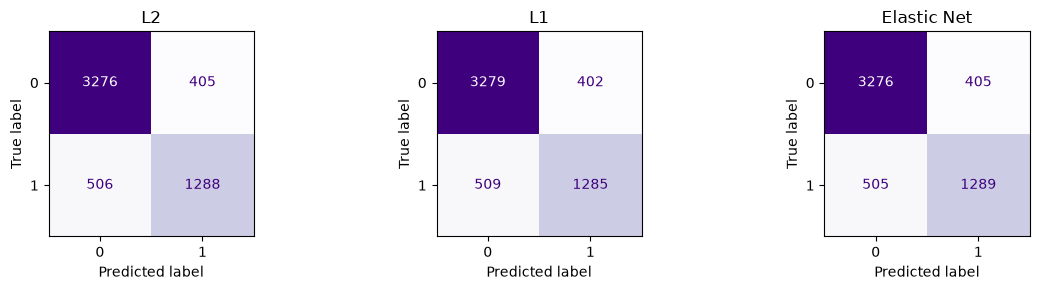

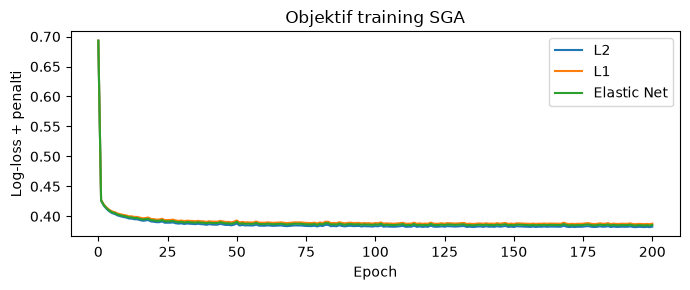

In [16]:
models, validation_predictions, validation_scores = evaluate_variants(
    X_train_model, y_train, X_val_model, y_val,
)
selected_variant = select_variant(validation_scores)
selected_config = FINAL_CONFIGS[selected_variant].copy()
model = models[selected_variant]
y_val_pred = validation_predictions[selected_variant]
display(validation_scores.join(cv_scores))
print('Varian terpilih:', VARIANT_NAMES[selected_variant])

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, name in zip(axes, FINAL_CONFIGS):
    ConfusionMatrixDisplay.from_predictions(
        y_val, validation_predictions[name], labels=[0, 1],
        ax=ax, colorbar=False, cmap='Purples',
    )
    ax.set_title(VARIANT_NAMES[name])
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3))
for name, fitted in models.items():
    ax.plot(fitted.loss_history_, label=VARIANT_NAMES[name])
ax.set(xlabel='Epoch', ylabel='Log-loss + penalti', title='Objektif training SGA')
ax.legend()
plt.tight_layout()
plt.show()


### Insight

Pemilihan menggunakan macro F1 validasi. Recall kelas batal menunjukkan bagian
pembatalan yang terdeteksi, false positive menunjukkan booking tidak batal yang
salah ditandai. Kurva objective SGA dapat berfluktuasi karena update per sampel.

---

# Comparison with scikit-learn <a name="8"></a>

---

Pembanding memakai matriks fitur dan threshold yang sama. Kekuatan penalti
disetarakan melalui `C = 1 / (n_train × reg_strength)`. L2 menggunakan L-BFGS,
L1 dan Elastic Net menggunakan SAGA. Toleransi L1 adalah `1e-4`, sedangkan
L2 dan Elastic Net `1e-7`, dengan maksimum 10.000 iterasi.

,macro_f1,precision_0,recall_0,f1-score_0,precision_1,recall_1,f1-score_1,true_negative,false_positive,false_negative,...,sklearn_precision_0,sklearn_recall_0,sklearn_f1-score_0,sklearn_precision_1,sklearn_recall_1,sklearn_f1-score_1,sklearn_true_negative,sklearn_false_positive,sklearn_false_negative,sklearn_true_positive
variant,,,,,,,,,,,,,,,,,,,,,
l2,0.808338,0.866208,0.889976,0.877931,0.760780,0.717949,0.738744,3276,405,506,...,0.867320,0.889704,0.878369,0.761036,0.720736,0.740338,3275,406,501,1293
l1,0.808161,0.865628,0.890791,0.878029,0.761707,0.716276,0.738294,3279,402,509,...,0.865466,0.887802,0.876492,0.756916,0.716834,0.736330,3268,413,508,1286
elasticnet,0.808577,0.866437,0.889976,0.878049,0.760921,0.718506,0.739106,3276,405,505,...,0.866720,0.888617,0.877532,0.758965,0.719621,0.738770,3271,410,503,1291


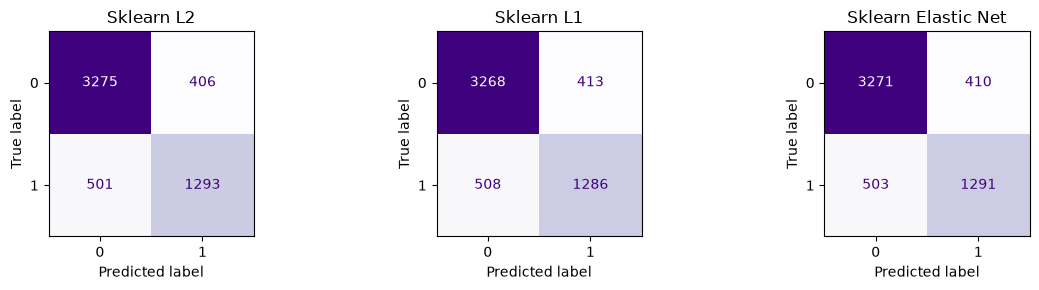

In [17]:
comparison_predictions, comparison_scores = compare_sklearn(
    X_train_model, y_train, X_val_model, y_val,
)
comparison_summary = validation_scores.join(cv_scores).join(
    comparison_scores.add_prefix('sklearn_')
)
display(comparison_summary)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, name in zip(axes, FINAL_CONFIGS):
    ConfusionMatrixDisplay.from_predictions(
        y_val, comparison_predictions[name], labels=[0, 1],
        ax=ax, colorbar=False, cmap='Purples',
    )
    ax.set_title(f'Sklearn {VARIANT_NAMES[name]}')
plt.tight_layout()
plt.show()


### Insight

Skor tiap model dipasangkan dengan pembanding pada regularisasi yang sama.
Perbedaan hasil dapat muncul karena metode optimasi dan anggaran training
berbeda. Model yang digunakan untuk submission adalah implementasi dari nol.

---

# Saving and Loading Models <a name="9"></a>

---

Preprocessing di-fit ulang pada seluruh train dan digunakan oleh ketiga model
full-train. Bundle menyimpan bobot, bias, konfigurasi, preprocessing terlatih,
versi pustaka, dan hasil validasi. Setiap regularisasi memiliki folder model sendiri.

In [18]:
input_hashes = data_hashes(CFG.DATA_DIR)
model_paths = fit_final_models(train_df, feature_columns, CFG.OUTPUT_DIR, {
    'validation': comparison_summary.to_dict(orient='index'),
    'internal_cv_folds': cv_folds.to_dict(orient='records'),
    'data_hashes': input_hashes,
    'selected_variant': selected_variant,
})
for name, path in model_paths.items():
    loaded_preprocessor, loaded_model = load_model_bundle(path)
    print(VARIANT_NAMES[name], '|', loaded_model.n_features_in_, 'fitur |', path.relative_to(CFG.ROOT_DIR))


L2 | 335 fitur | output/final/model/logistic_regression/l2/model_bundle.pkl
L1 | 335 fitur | output/final/model/logistic_regression/l1/model_bundle.pkl
Elastic Net | 335 fitur | output/final/model/logistic_regression/elasticnet/model_bundle.pkl


### Insight

Bundle menyimpan parameter model, bukan objek kelas dari sesi notebook.
Setelah dimuat, kelas SGA direkonstruksi dari source `.py`. Prediksi juga
diperiksa pada proses Python baru pada bagian submission.

---

# Kaggle Submission <a name="10"></a>

---

CSV tiap regularisasi dibuat dari model yang dimuat dari disk. Header, urutan
ID, jumlah baris, label integer, dan hash CSV diperiksa. CSV utama LR berasal
dari varian dengan macro F1 validasi tertinggi, nama varian menjadi pemecah seri.

In [19]:
submission_summary, submission_path = make_submissions(
    model_paths, test_df, CFG.TEST_PATH, CFG.OUTPUT_DIR,
    selected_variant,
)
display(submission_summary)
results_dir = CFG.MODEL_DIR
comparison_summary.join(submission_summary).to_csv(results_dir / 'validation.csv')
display(pd.read_csv(submission_path, dtype={'id': str}).head())
print('CSV utama LR:', submission_path.relative_to(CFG.ROOT_DIR))


Submission L2 disimpan.


Submission L1 disimpan.


Submission Elastic Net disimpan.


,rows,csv
variant,,
l2,6844,final/model/logistic_regression/l2/submission.csv
l1,6844,final/model/logistic_regression/l1/submission.csv
elasticnet,6844,final/model/logistic_regression/elasticnet/sub...


,id,is_canceled
0,5cb6f473,0
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


CSV utama LR: output/final/model/logistic_regression/submission.csv


### Insight

Setiap regularisasi menghasilkan CSV dengan kolom `id,is_canceled`, satu label
integer 0 atau 1 untuk setiap booking test. Tabel di atas menunjukkan jumlah
baris dan lokasi berkas. CSV dapat diunggah secara manual ke kompetisi Kaggle.

Seluruh keluaran LR berada di `output/final/model/logistic_regression/`.
Subfolder `l1`, `l2`, dan `elasticnet` masing-masing berisi model dan CSV.
`submission.csv` pada folder utama LR berasal dari varian terpilih, sedangkan
`validation.csv` mencatat hasil evaluasi. Run All menimpa hasil pada lokasi yang sama.

---

# Error Analysis <a name="11"></a>

---

Analisis berikut memakai prediksi holdout dari konfigurasi yang sudah
ditetapkan. Jenis kesalahan ditinjau menurut channel dan waktu pemesanan,
tanpa mengubah parameter berdasarkan label test.

In [20]:
error_analysis = X_val_raw.copy()
error_analysis['actual'] = y_val
error_analysis['predicted'] = y_val_pred
error_analysis['error_type'] = np.select(
    [error_analysis['actual'].eq(0) & error_analysis['predicted'].eq(1),
     error_analysis['actual'].eq(1) & error_analysis['predicted'].eq(0)],
    ['false_positive', 'false_negative'], default='correct',
)
display(error_analysis['error_type'].value_counts())
display(pd.crosstab(error_analysis['booking_channel'], error_analysis['error_type']))
error_analysis['lead_group'] = pd.cut(
    error_analysis['days_before_arrival'], [-np.inf, 7, 30, 90, 180, np.inf]
)
display(pd.crosstab(error_analysis['lead_group'], error_analysis['error_type']))
display(error_analysis.loc[error_analysis['error_type'] != 'correct'].head(20))


error_type
correct           4565
false_negative     505
false_positive     405
Name: count, dtype: int64

error_type,correct,false_negative,false_positive
booking_channel,,,
Airline,9,4,0
Complimentary,59,0,1
Corporate,299,22,3
Offline Agent,1366,135,102
Online Travel Agent,2832,344,299


error_type,correct,false_negative,false_positive
lead_group,,,
"(-inf, 7.0]",749,84,5
"(7.0, 30.0]",860,77,45
"(30.0, 90.0]",1276,143,124
"(90.0, 180.0]",890,143,124
"(180.0, inf]",618,28,95


,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,...,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,actual,predicted,error_type,lead_group
35,2.0,0.0,2,4,Breakfast,0.0,Type B,156.0,2024,4,...,Offline Agent,0,0,0,1456000.0,0.0,1,0,false_negative,"(90.0, 180.0]"
44,1.0,0.0,0,2,Half Board,0.0,Type B,100.0,2023,10,...,Online Travel Agent,0,0,0,1303000.0,0.0,1,0,false_negative,"(90.0, 180.0]"
55,1.0,0.0,1,1,NaN,0.0,Type B,306.0,2024,7,...,Offline Agent,0,0,0,1528000.0,0.0,0,1,false_positive,"(180.0, inf]"
69,2.0,0.0,2,4,Breakfast,0.0,Type G,26.0,2024,3,...,Online Travel Agent,0,0,0,1697000.0,0.0,0,1,false_positive,"(7.0, 30.0]"
81,2.0,0.0,0,2,NaN,0.0,Type B,98.0,2023,10,...,Offline Agent,0,0,0,1690000.0,0.0,1,0,false_negative,"(90.0, 180.0]"
83,2.0,0.0,2,3,Breakfast,0.0,Type B,191.0,2024,11,...,Offline Agent,0,0,0,NaN,NaN,0,1,false_positive,"(180.0, inf]"
86,1.0,0.0,1,2,Breakfast,0.0,Type B,113.0,2024,6,...,Offline Agent,0,0,0,1796000.0,0.0,0,1,false_positive,"(90.0, 180.0]"
91,2.0,0.0,0,3,Breakfast,0.0,NaN,24.0,2024,10,...,Online Travel Agent,0,0,0,NaN,0.0,0,1,false_positive,"(7.0, 30.0]"
105,1.0,0.0,0,2,Breakfast,0.0,Type B,192.0,2024,6,...,Offline Agent,0,0,0,1574000.0,0.0,0,1,false_positive,"(180.0, inf]"
136,2.0,0.0,0,1,Breakfast,0.0,Type G,88.0,2024,9,...,Online Travel Agent,0,0,0,2395000.0,1.0,1,0,false_negative,"(30.0, 90.0]"


### Insight

Pada holdout, Elastic Net memperoleh macro F1 **0,808577**,
dengan precision kelas batal **76,09%** dan recall
**71,85%**. Terdapat **505 pembatalan terlewat**
dan **405 booking tidak batal yang salah ditandai**.
Model masih lebih sulit mengenali pembatalan daripada booking yang tidak batal.
Distribusi kesalahan per kelompok perlu dibaca bersama ukuran kelompoknya.

Metrik di atas berasal dari validasi lokal. Skor Kaggle dihitung pada sampel
berbeda dan dicatat terpisah dari hasil holdout.

### Referensi

- Materi11-LinearLogisticRegression, IF3170, semester I 2026/2027, hlm. 28–29 — SGA per sampel.
- M. L. Khodra, "Logistic Regression: What & Why," YouTube, 2021. [Video]. Available: https://www.youtube.com/watch?v=QAKZ_pymEzc.
- [scikit-learn: Logistic Regression](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) — bentuk penalti dan objektif model pembanding.
- [scikit-learn: Common Pitfalls](https://scikit-learn.org/stable/common_pitfalls.html) — pemisahan fit dan transform preprocessing.
